# DAZONE 2026 — RUAD Adversarial Feature Desensitization Uplift Model

Notebook này được chỉnh từ `top_2.ipynb`.

Thay đổi chính:
- **Đã loại bỏ toàn bộ quá trình train `INT_RF` và `UPLIFT_RF_CIT`**.
- Chỉ giữ lại model sau khi tích hợp ý tưởng paper **Robustness-enhanced Uplift Modeling with Adversarial Feature Desensitization (RUAD)**.
- Model mới: **RUAD_SNN** cho cả `cash_sign_30d` và `card_sign_30d`.

Ý tưởng RUAD được tích hợp:
- Feature selection / feature mask để chọn nhóm feature nhạy cảm.
- Joint multi-label loss gồm:
  - response loss trên outcome thật `y`
  - transformed-outcome loss để học trực tiếp uplift.
- Adversarial Feature Desensitization:
  - tạo nhiễu đối kháng trên nhóm feature được mask
  - soft interpolation giữa sample gốc và adversarial sample
  - ép uplift prediction ổn định hơn khi feature nhạy cảm bị perturb.

Cách chạy:
1. Điền `feat_path` và `tgt_path` trong cell load data nếu notebook không tự có path.
2. Chạy lần lượt các cell.
3. Xem kết quả chính ở Logs: `Qini_coefficient_cash`, `Qini_coefficient_card`, `Qini_coefficient_total`.

In [1]:
# ============================================================
# 0. MINIMAL ENVIRONMENT SETUP
# ============================================================
# RUAD dùng PyTorch + sklearn + pandas/numpy.
# Không cần causalml, vì đã loại bỏ UPLIFT_RF_CIT.

import importlib.util

required_imports = ["torch", "sklearn", "pandas", "numpy"]
missing = [pkg for pkg in required_imports if importlib.util.find_spec(pkg) is None]
if missing:
    raise ImportError(f"Thiếu package: {missing}. Trên Kaggle thường cần bật internet hoặc cài package trước khi chạy.")

print("Environment OK: torch/sklearn/pandas/numpy available")

Environment OK: torch/sklearn/pandas/numpy available


In [2]:
# ============================================================
# 1. IMPORTS + GLOBAL CONFIG
# ============================================================
import gc
import os
import re
import time
import random
import warnings
from pathlib import Path

# Giới hạn thread để ổn định runtime trên Kaggle/CPU.
os.environ.setdefault("OMP_NUM_THREADS", "4")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "4")
os.environ.setdefault("MKL_NUM_THREADS", "4")
os.environ.setdefault("NUMEXPR_NUM_THREADS", "4")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

try:
    from IPython.display import display
except Exception:
    display = print

warnings.filterwarnings("ignore")

SEED = 42
N_SPLITS = 5
N_JOBS = 4

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# ============================================================
# RUAD CONFIG
# ============================================================
SELECTED_MODEL_NAMES = ["RUAD_SNN"]

RUAD_HIDDEN_DIMS = [256, 128]
RUAD_DROPOUT = 0.12
RUAD_EPOCHS = 18
RUAD_BATCH_SIZE = 4096
RUAD_LR = 1e-3
RUAD_WEIGHT_DECAY = 1e-5
RUAD_PATIENCE = 5

# Tỷ lệ feature được xem là key/sensitive feature trong mask.
RUAD_KAPPA = 0.30

# Joint multi-label objective: alpha ưu tiên transformed-outcome/uplift loss.
RUAD_ALPHA = 0.45

# Adversarial feature desensitization.
RUAD_BETA = 0.20
RUAD_ADV_EPS = 0.035
RUAD_ADV_STEPS = 1
RUAD_ADV_CLAMP = 0.10
RUAD_USE_AUTOCAST = bool(torch.cuda.is_available())

# Transformed outcome thường có biên lớn khi propensity nhỏ; RCT trong bài toán này gần cân bằng,
# nhưng vẫn clip để training ổn định.
RUAD_YSTAR_CLIP = 8.0

Device: cpu


## 2. Load dữ liệu + feature dropping

In [3]:
# ============================================================
# 2. LOAD DATA + FEATURE DROPPING CONFIG
# ============================================================

FEATURE_DROP_PRIORITY_LIST = [
    "cnt_month_over3_credit_card_6m",
    "cnt_connected_tls",
    "cnt_earlyterminted_pos",
    "min_sign_vol",
    "cli_contact_region_population_grp",
    "cnt_inbound_tls_12m",
    "cnt_bank_inst_appl_12m",
    "f_approve_last_process",
    "worst_credit_status",
    "cli_contact_region_level",
    "cli_education",
    "f_ever_default",
    "cli_age",
    "cli_job",
    "cnt_earlyterminated_cash",
    "amt_terminated_loan_12m",
    "cnt_noinsurance_loan_24m",
    "cnt_report_bank_6m",
    "ratio_conn_tls_endmonth_12m",
    "ratio_conn_tls_weekend_12m",
    "cli_marital_status",
    "avg_sign_vol",
    "cnt_terminated_loan_12m",
    "cnt_fail_tls_3m",
    "last_offer_limit",
    "cli_emp_period",
    "cnt_fi_inst_appl_12m",
    "cnt_total_payment",
    "risk_grp",
    "cnt_lender_has2pay_last_24m",
    "cnt_month_status1",
    "last_process_channel",
    "cnt_month_from_last_appl",
    "cnt_report_institution_12m",
]

# Tùy chỉnh feature dropping:
#   None -> baseline, không drop feature nào.
#   int  -> drop 1 feature theo ID. Ví dụ: COL_IDX = 0.
#   list/tuple/set/range -> drop nhiều feature. Ví dụ: COL_IDX = [2, 3, 4, 5].
#   list(range(a, b)) -> drop liên tiếp ID a..b-1. Ví dụ: list(range(2, 6)) = 2,3,4,5.
#   string "a:b" -> drop liên tiếp ID a..b-1. Ví dụ: "2:6" = 2,3,4,5.
#   string/list tên feature -> drop trực tiếp theo tên feature gốc. Ví dụ: ["cli_age", "risk_grp"].
#
# Ví dụ chạy:
#   COL_IDX = None
#   COL_IDX = 0
#   COL_IDX = [2, 3]
#   COL_IDX = list(range(2, 6))
#   COL_IDX = "2:6"
COL_IDX = None

feat_path = "/kaggle/input/datasets/tmtrnhelloworld/feature-eng-data-daz/df_feature.csv"
tgt_path = "/kaggle/input/datasets/tmtrnhelloworld/feature-eng-data-daz/df_target.csv"

# Nếu để trống, tự tìm file thường dùng trên Kaggle/working.
def _auto_find_csv(candidates):
    roots = [Path("/kaggle/input"), Path("/kaggle/working"), Path("/mnt/data"), Path(".")]
    for root in roots:
        if not root.exists():
            continue
        for name in candidates:
            hits = list(root.rglob(name))
            if hits:
                return str(hits[0])
    return ""

if not feat_path:
    feat_path = _auto_find_csv(["df_feature.csv", "feature.csv", "features.csv"])
if not tgt_path:
    tgt_path = _auto_find_csv(["df_target.csv", "target.csv", "targets.csv"])

print("feat_path:", feat_path)
print("tgt_path :", tgt_path)
if not feat_path or not tgt_path:
    raise FileNotFoundError("Không tìm thấy df_feature.csv hoặc df_target.csv. Hãy điền feat_path và tgt_path thủ công trong cell này.")

TARGET_CASH = "cash_sign_30d"
TARGET_CARD = "card_sign_30d"
TREAT_COL_BINARY = "treatment_cash"
TREAT_COL_RAW = "treatment"
ID_CANDIDATES = ["id", "ID", "row_id", "customer_id", "Customer_ID", "client_id", "cli_id", "app_id", "application_id"]


def normalize_feature_drop_selection(selection):
    """Chuẩn hóa cấu hình drop feature.

    Trả về:
    - drop_ids: list ID trong FEATURE_DROP_PRIORITY_LIST.
    - drop_base_cols: list tên feature gốc cần drop.

    Hỗ trợ:
    - None
    - int
    - list/tuple/set/range chứa int hoặc tên feature
    - string "a:b" để drop ID a..b-1
    - string tên feature gốc
    """
    if selection is None:
        return [], []

    def _expand_one(item):
        if isinstance(item, str):
            s = item.strip()
            if not s:
                return []
            if re.fullmatch(r"\d+", s):
                return [int(s)]
            m = re.fullmatch(r"(\d+)\s*:\s*(\d+)", s)
            if m:
                start, stop = int(m.group(1)), int(m.group(2))
                return list(range(start, stop))
            return [s]
        if isinstance(item, (int, np.integer)):
            return [int(item)]
        if isinstance(item, range):
            return list(item)
        if isinstance(item, slice):
            start = 0 if item.start is None else item.start
            stop = len(FEATURE_DROP_PRIORITY_LIST) if item.stop is None else item.stop
            step = 1 if item.step is None else item.step
            return list(range(start, stop, step))
        raise TypeError(
            "COL_IDX chỉ hỗ trợ None, int, range, slice, str, "
            "hoặc list/tuple/set chứa int/tên feature."
        )

    if isinstance(selection, (list, tuple, set, range, np.ndarray, pd.Series)):
        raw_items = []
        for item in list(selection):
            raw_items.extend(_expand_one(item))
    else:
        raw_items = _expand_one(selection)

    drop_ids = []
    drop_base_cols = []
    seen_cols = set()

    for item in raw_items:
        if isinstance(item, (int, np.integer)):
            idx = int(item)
            if idx < 0 or idx >= len(FEATURE_DROP_PRIORITY_LIST):
                raise IndexError(f"COL_IDX={idx} ngoài range 0..{len(FEATURE_DROP_PRIORITY_LIST)-1}")
            base_col = FEATURE_DROP_PRIORITY_LIST[idx]
            if base_col not in seen_cols:
                drop_ids.append(idx)
                drop_base_cols.append(base_col)
                seen_cols.add(base_col)
        elif isinstance(item, str):
            base_col = item.strip()
            if base_col not in FEATURE_DROP_PRIORITY_LIST:
                print(f"WARNING: '{base_col}' không nằm trong FEATURE_DROP_PRIORITY_LIST, vẫn sẽ thử match trong df_feature.")
                idx = None
            else:
                idx = FEATURE_DROP_PRIORITY_LIST.index(base_col)
            if base_col not in seen_cols:
                drop_ids.append(idx)
                drop_base_cols.append(base_col)
                seen_cols.add(base_col)
        else:
            raise TypeError(f"COL_IDX chứa phần tử không hợp lệ: {item!r}")

    return drop_ids, drop_base_cols


def match_base_feature_columns(columns, base_col):
    """Match cột gốc và các cột one-hot/encoded sinh ra từ feature gốc."""
    if base_col is None:
        return []
    return [c for c in columns if c == base_col or c.startswith(f"{base_col}_")]


def make_id_series(source_df, n_rows=None, id_col=None):
    if n_rows is None:
        n_rows = len(source_df)
    if id_col is not None and id_col in source_df.columns:
        return source_df[id_col].reset_index(drop=True).rename(id_col)
    return pd.Series(np.arange(n_rows), name="row_id")


def encode_treatment_cash(feature_df):
    """Return W: 1 = Cash strategy, 0 = Card strategy."""
    if TREAT_COL_BINARY in feature_df.columns:
        return feature_df[TREAT_COL_BINARY].astype(int).to_numpy(), TREAT_COL_BINARY
    if TREAT_COL_RAW not in feature_df.columns:
        raise ValueError("Thiếu cột treatment_cash hoặc treatment trong df_feature.csv")

    s = feature_df[TREAT_COL_RAW]
    if pd.api.types.is_numeric_dtype(s):
        return s.astype(int).to_numpy(), TREAT_COL_RAW

    st = s.astype(str).str.strip().str.lower()
    mapped = np.where(st.str.contains("cash"), 1, np.where(st.str.contains("card"), 0, np.nan))
    if np.isnan(mapped).any():
        bad = sorted(st[pd.isna(mapped)].unique()[:10])
        raise ValueError(f"Không encode được treatment values: {bad}")
    return mapped.astype(int), TREAT_COL_RAW




feat = pd.read_csv(feat_path)
tgt = pd.read_csv(tgt_path)

W, TREAT_COL = encode_treatment_cash(feat)
Y_cash = tgt[TARGET_CASH].astype(int).to_numpy()
Y_card = tgt[TARGET_CARD].astype(int).to_numpy()

ID_COL = next((col for col in ID_CANDIDATES if col in feat.columns), None)
FEATURE_DROP_IDXS, FEATURE_DROP_BASE_COLS = normalize_feature_drop_selection(COL_IDX)
FEATURE_DROP_BASE_COL = None if len(FEATURE_DROP_BASE_COLS) == 0 else "|".join(FEATURE_DROP_BASE_COLS)
FEATURE_DROP_COL_IDX = None if len(FEATURE_DROP_IDXS) == 0 else "|".join("NA" if i is None else str(i) for i in FEATURE_DROP_IDXS)

drop_cols_in_feat = []
for base_col in FEATURE_DROP_BASE_COLS:
    drop_cols_in_feat.extend(match_base_feature_columns(feat.columns, base_col))
# Deduplicate while preserving order.
drop_cols_in_feat = list(dict.fromkeys(drop_cols_in_feat))

index_like_cols = [c for c in feat.columns if c.lower().startswith("unnamed") or c.lower() == "index"]
exclude_cols = set(drop_cols_in_feat + index_like_cols + [TARGET_CASH, TARGET_CARD, TREAT_COL_BINARY, TREAT_COL_RAW])
if ID_COL is not None:
    exclude_cols.add(ID_COL)

FEAT_COLS = [col for col in feat.columns if col not in exclude_cols]
X_df = feat[FEAT_COLS].copy()
X = X_df.to_numpy(dtype=np.float32)

w_cash = (W == 1).astype(int)
w_card = (W == 0).astype(int)

print("=" * 80)
if not FEATURE_DROP_BASE_COLS:
    print("FEATURE DROPPING: baseline, không drop feature nào")
else:
    print(f"FEATURE DROPPING: COL_IDX={COL_IDX}")
    print(f"Drop IDs      : {FEATURE_DROP_IDXS}")
    print(f"Base features : {FEATURE_DROP_BASE_COLS}")
    print(f"Dropped df_feature columns ({len(drop_cols_in_feat)}): {drop_cols_in_feat}")
print("=" * 80)

print(f"N={len(X):,} | features={X.shape[1]}")
print(f"Treatment Cash: {W.sum():,} ({W.mean():.2%}) | Card: {(1-W).sum():,} ({(1-W).mean():.2%})")
print(f"Cash target rate: {Y_cash.mean():.4%} | Card target rate: {Y_card.mean():.4%}")
print("Feature NaN total:", int(pd.isna(X_df).sum().sum()))


feat_path: /kaggle/input/datasets/tmtrnhelloworld/feature-eng-data-daz/df_feature.csv
tgt_path : /kaggle/input/datasets/tmtrnhelloworld/feature-eng-data-daz/df_target.csv
FEATURE DROPPING: baseline, không drop feature nào
N=136,992 | features=62
Treatment Cash: 75,612 (55.19%) | Card: 61,380 (44.81%)
Cash target rate: 5.9186% | Card target rate: 2.7111%
Feature NaN total: 0


In [4]:
# ============================================================
# 3. OPTIONAL TEST FEATURE LOADING
# ============================================================
# Notebook chỉ dùng test file đã clean/one-hot tương thích với df_feature.csv.
# Nếu không có test feature đã clean, phần submission sẽ tự skip.


def find_optional_test_feature():
    names = ["df_feature_test.csv", "test_feature.csv", "X_test.csv", "test.csv"]
    roots = [p for p in [Path("/kaggle/input"), Path("/kaggle/working"), Path.cwd(), Path.cwd() / "data", Path("/mnt/data")]
             if p.exists() and str(p.resolve()) not in ["/", "/mnt"]]
    for root in roots:
        for name in names:
            direct = root / name
            if direct.exists():
                return direct
            try:
                hits = list(root.rglob(name))
                if hits:
                    return sorted(hits, key=lambda p: len(str(p)))[0]
            except Exception:
                pass
    return None


def build_test_matrix(test_feature_path):
    test_feat = pd.read_csv(test_feature_path)
    test_id_col = next((col for col in ID_CANDIDATES if col in test_feat.columns), None)
    test_id = make_id_series(test_feat, id_col=test_id_col)

    # Align đúng FEAT_COLS của train: thiếu cột thì fill 0, thừa cột thì bỏ.
    X_test_df = test_feat.reindex(columns=FEAT_COLS, fill_value=0).copy()
    return test_feat, test_id, X_test_df, X_test_df.to_numpy(dtype=np.float32)


test_path = find_optional_test_feature()
if test_path is None:
    test_feat = None
    test_id = None
    X_test_df = None
    X_test = None
    print("Không tìm thấy test feature đã clean -> skip submission.")
else:
    test_feat, test_id, X_test_df, X_test = build_test_matrix(test_path)
    print("Test feature path:", test_path)
    print(f"X_test shape={X_test.shape}")


Không tìm thấy test feature đã clean -> skip submission.


In [5]:
# ============================================================
# 4. LEAKAGE AUDIT
# ============================================================
FORBIDDEN_FEATURE_COLS = {TARGET_CASH, TARGET_CARD, TREAT_COL_BINARY, TREAT_COL_RAW}
if ID_COL is not None:
    FORBIDDEN_FEATURE_COLS.add(ID_COL)

forbidden_present = sorted([c for c in FEAT_COLS if c in FORBIDDEN_FEATURE_COLS])
assert not forbidden_present, f"DATA LEAKAGE: các cột không được phép đang nằm trong FEAT_COLS: {forbidden_present}"

assert TARGET_CASH not in FEAT_COLS and TARGET_CARD not in FEAT_COLS, "DATA LEAKAGE: target bị đưa vào X"
assert TREAT_COL_BINARY not in FEAT_COLS and TREAT_COL_RAW not in FEAT_COLS, "DATA LEAKAGE: treatment bị đưa vào X"
if ID_COL is not None:
    assert ID_COL not in FEAT_COLS, "DATA LEAKAGE/RISK: ID bị đưa vào X"

feature_drop_audit = pd.DataFrame({
    "base_feature": FEATURE_DROP_PRIORITY_LIST,
    "n_matched_train_cols": [len(match_base_feature_columns(feat.columns, c)) for c in FEATURE_DROP_PRIORITY_LIST],
    "matched_train_cols": [match_base_feature_columns(feat.columns, c) for c in FEATURE_DROP_PRIORITY_LIST],
})

print("Leakage audit: PASSED")
display(feature_drop_audit)


Leakage audit: PASSED


,base_feature,n_matched_train_cols,matched_train_cols
0,cnt_month_over3_credit_card_6m,1,[cnt_month_over3_credit_card_6m]
1,cnt_connected_tls,1,[cnt_connected_tls]
2,cnt_earlyterminted_pos,1,[cnt_earlyterminted_pos]
3,min_sign_vol,1,[min_sign_vol]
4,cli_contact_region_population_grp,3,"[cli_contact_region_population_grp_RURAL, cli_..."
5,cnt_inbound_tls_12m,1,[cnt_inbound_tls_12m]
6,cnt_bank_inst_appl_12m,1,[cnt_bank_inst_appl_12m]
7,f_approve_last_process,1,[f_approve_last_process]
8,worst_credit_status,1,[worst_credit_status]
9,cli_contact_region_level,2,"[cli_contact_region_level_North, cli_contact_r..."


## 3. Qini metric + fold cố định

In [6]:
# ============================================================
# 5. QINI METRIC + FIXED FOLDS
# ============================================================
_trapz = np.trapezoid if hasattr(np, "trapezoid") else np.trapz


def qini_curve(y, w_event, score):
    y = np.asarray(y, dtype=float)
    w_event = np.asarray(w_event, dtype=int)
    score = np.asarray(score, dtype=float)

    order = np.argsort(-score, kind="mergesort")
    y_s = y[order]
    w_s = w_event[order]

    n_t = max(int(w_event.sum()), 1)
    n_c = max(len(w_event) - n_t, 1)
    q = np.cumsum(y_s * w_s) / n_t - np.cumsum(y_s * (1 - w_s)) / n_c
    x = np.arange(1, len(y) + 1) / len(y)
    return np.r_[0.0, x], np.r_[0.0, q]


def oracle_score(y, w_event):
    y = np.asarray(y, dtype=int)
    w_event = np.asarray(w_event, dtype=int)
    return w_event * y - (1 - w_event) * y


def qini_metrics(y, w_event, score):
    x, q = qini_curve(y, w_event, score)
    auc_model = float(_trapz(q, x))
    ate = float(q[-1])
    auc_random = ate * 0.5
    _, q_perfect = qini_curve(y, w_event, oracle_score(y, w_event))
    auc_perfect = float(_trapz(q_perfect, x))

    qini_diff = auc_model - auc_random
    denom = auc_perfect - auc_random
    qini_norm = qini_diff / denom if abs(denom) > 1e-12 else np.nan
    qini_ratio = auc_model / auc_random if abs(auc_random) > 1e-12 else np.nan
    return {
        "ate": ate,
        "auc_model": auc_model,
        "auc_random": auc_random,
        "auc_perfect": auc_perfect,
        "qini_diff": qini_diff,
        "qini_norm": qini_norm,
        "qini_ratio": qini_ratio,
    }


def make_fold_id(w_event, y):
    key = (np.asarray(w_event, dtype=int) * 2 + np.asarray(y, dtype=int)).astype(int)
    skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
    fold_id = np.zeros(len(y), dtype=int)
    dummy_x = np.zeros(len(y))
    for fold, (_, va) in enumerate(skf.split(dummy_x, key), 1):
        fold_id[va] = fold
    return fold_id


fold_ids = {
    "cash": make_fold_id(w_cash, Y_cash),
    "card": make_fold_id(w_card, Y_card),
}

print("Fold distribution cash target:", pd.Series(fold_ids["cash"]).value_counts().sort_index().to_dict())
print("Fold distribution card target:", pd.Series(fold_ids["card"]).value_counts().sort_index().to_dict())


Fold distribution cash target: {1: 27399, 2: 27399, 3: 27398, 4: 27398, 5: 27398}
Fold distribution card target: {1: 27399, 2: 27399, 3: 27398, 4: 27398, 5: 27398}


## 4. Model helpers: RUAD

In [7]:
# ============================================================
# 6. RUAD MODEL HELPERS
# ============================================================
class RUADNet(nn.Module):
    """Neural uplift model có global feature mask + two-head response model.

    - masker_logits học importance/mask của từng feature.
    - forward_response trả về mu0, mu1.
    - uplift = mu1 - mu0.
    """
    def __init__(self, n_features, hidden_dims=(256, 128), dropout=0.1):
        super().__init__()
        self.n_features = int(n_features)
        self.masker_logits = nn.Parameter(torch.zeros(self.n_features))

        layers = []
        in_dim = self.n_features
        for h in hidden_dims:
            layers += [nn.Linear(in_dim, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(dropout)]
            in_dim = h
        self.backbone = nn.Sequential(*layers)
        self.head0 = nn.Linear(in_dim, 1)
        self.head1 = nn.Linear(in_dim, 1)

    def soft_mask(self):
        return torch.sigmoid(self.masker_logits)

    def topk_mask(self, kappa=0.30):
        k = max(1, int(round(kappa * self.n_features)))
        score = self.soft_mask()
        idx = torch.topk(score, k=k, largest=True).indices
        hard = torch.zeros_like(score)
        hard[idx] = 1.0
        # Straight-through mask: forward hard, backward soft.
        return hard + score - score.detach()

    def forward_response(self, x):
        h = self.backbone(x)
        mu0 = torch.sigmoid(self.head0(h)).squeeze(-1)
        mu1 = torch.sigmoid(self.head1(h)).squeeze(-1)
        return mu0, mu1

    def forward(self, x):
        return self.forward_response(x)

    def uplift(self, x):
        mu0, mu1 = self.forward_response(x)
        return mu1 - mu0


def get_target_arrays(target_name):
    if target_name == "cash":
        return Y_cash.astype(np.float32), w_cash.astype(np.float32), "CASH"
    if target_name == "card":
        return Y_card.astype(np.float32), w_card.astype(np.float32), "CARD"
    raise ValueError("target_name phải là 'cash' hoặc 'card'")


def fold_iter(target_name):
    fold_id = fold_ids[target_name]
    for fold in range(1, N_SPLITS + 1):
        va = np.where(fold_id == fold)[0]
        tr = np.where(fold_id != fold)[0]
        yield fold, tr, va


def bce_prob(pred, target):
    pred = pred.clamp(1e-5, 1 - 1e-5)
    return F.binary_cross_entropy(pred, target)


def mse_loss(pred, target):
    return F.mse_loss(pred, target)


def make_transformed_outcome(y, t_event, propensity):
    p = float(np.clip(propensity, 1e-3, 1 - 1e-3))
    y_star = y / p * t_event - y / (1 - p) * (1 - t_event)
    return np.clip(y_star, -RUAD_YSTAR_CLIP, RUAD_YSTAR_CLIP).astype(np.float32)


def predict_ruad(model, X_np, batch_size=8192):
    model.eval()
    preds = []
    with torch.no_grad():
        for start in range(0, len(X_np), batch_size):
            xb = torch.as_tensor(X_np[start:start + batch_size], dtype=torch.float32, device=device)
            preds.append(model.uplift(xb).detach().cpu().numpy())
    return np.concatenate(preds).astype(np.float32)


def ruad_train_one_fold(X_tr, y_tr, t_tr, X_va, y_va, t_va, seed):
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    y_tr = y_tr.astype(np.float32)
    t_tr = t_tr.astype(np.float32)
    y_va = y_va.astype(np.float32)
    t_va = t_va.astype(np.float32)

    propensity = float(np.mean(t_tr))
    ystar_tr = make_transformed_outcome(y_tr, t_tr, propensity)

    ds = TensorDataset(
        torch.as_tensor(X_tr, dtype=torch.float32),
        torch.as_tensor(y_tr, dtype=torch.float32),
        torch.as_tensor(t_tr, dtype=torch.float32),
        torch.as_tensor(ystar_tr, dtype=torch.float32),
    )
    loader = DataLoader(ds, batch_size=RUAD_BATCH_SIZE, shuffle=True, drop_last=False, num_workers=0)

    model = RUADNet(X_tr.shape[1], hidden_dims=RUAD_HIDDEN_DIMS, dropout=RUAD_DROPOUT).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=RUAD_LR, weight_decay=RUAD_WEIGHT_DECAY)
    scaler = torch.cuda.amp.GradScaler(enabled=RUAD_USE_AUTOCAST)

    best_state = None
    best_qini = -np.inf
    bad_epochs = 0

    for epoch in range(1, RUAD_EPOCHS + 1):
        model.train()
        losses = []
        for xb, yb, tb, ysb in loader:
            xb = xb.to(device)
            yb = yb.to(device)
            tb = tb.to(device)
            ysb = ysb.to(device)

            optimizer.zero_grad(set_to_none=True)

            with torch.cuda.amp.autocast(enabled=RUAD_USE_AUTOCAST):
                mask = model.topk_mask(RUAD_KAPPA)
                xm = xb * mask
                mu0, mu1 = model(xm)
                mu_t = tb * mu1 + (1.0 - tb) * mu0
                uplift_m = mu1 - mu0

                # Lr: true response; Lo: transformed outcome/uplift target.
                loss_r = bce_prob(mu_t, yb)
                loss_o = mse_loss(uplift_m, ysb)

                # AFD: adversarial perturbation only on selected/sensitive features.
                xadv = xm.detach().clone()
                xadv.requires_grad_(True)
                with torch.enable_grad():
                    for _ in range(RUAD_ADV_STEPS):
                        adv_uplift = model.uplift(xadv)
                        adv_obj = mse_loss(adv_uplift, uplift_m.detach())
                        grad = torch.autograd.grad(adv_obj, xadv, retain_graph=True, create_graph=False)[0]
                        grad_norm = grad.norm(p=2, dim=1, keepdim=True).clamp_min(1e-8)
                        step = RUAD_ADV_EPS * grad / grad_norm
                        step = step * mask
                        xadv = (xadv + step).detach()
                        delta = (xadv - xm).clamp(-RUAD_ADV_CLAMP, RUAD_ADV_CLAMP) * mask
                        xadv = (xm + delta).detach()
                        xadv.requires_grad_(True)

                gamma = torch.rand((xb.size(0), 1), device=device)
                xsoft = gamma * xm + (1.0 - gamma) * xadv.detach()
                uplift_adv = model.uplift(xsoft)
                loss_a = mse_loss(uplift_adv, uplift_m.detach())

                loss = (1.0 - RUAD_ALPHA) * loss_r + RUAD_ALPHA * loss_o + RUAD_BETA * loss_a

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            scaler.step(optimizer)
            scaler.update()
            losses.append(float(loss.detach().cpu()))

        va_score = predict_ruad(model, X_va)
        va_qini = qini_metrics(y_va, t_va, va_score)["qini_norm"]
        va_qini_safe = -np.inf if pd.isna(va_qini) else float(va_qini)
        print(f"    epoch={epoch:02d} loss={np.mean(losses):.6f} val_qini={va_qini_safe:+.6f}")

        if va_qini_safe > best_qini:
            best_qini = va_qini_safe
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= RUAD_PATIENCE:
                print(f"    early stop at epoch={epoch}")
                break

    if best_state is not None:
        model.load_state_dict(best_state)
    return model, best_qini


def run_ruad_snn(target_name, X_test=None):
    y, w_event, label = get_target_arrays(target_name)
    oof = np.zeros(len(X), dtype=np.float32)
    test_score = np.zeros(len(X_test), dtype=np.float32) if X_test is not None else None

    print(f"\n[{label}] RUAD_SNN")
    for fold, tr, va in fold_iter(target_name):
        print(f"  Fold {fold}/{N_SPLITS} | train={len(tr):,} valid={len(va):,}")
        model, best_qini = ruad_train_one_fold(
            X[tr], y[tr], w_event[tr],
            X[va], y[va], w_event[va],
            seed=SEED + fold,
        )
        oof[va] = predict_ruad(model, X[va])
        if X_test is not None:
            test_score += predict_ruad(model, X_test) / N_SPLITS

        met = qini_metrics(y[va], w_event[va], oof[va])
        print(f"  [{label}] fold={fold} best_val_qini={best_qini:+.6f} final_qini={met['qini_norm']:+.6f}")
        del model
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    full_met = qini_metrics(y, w_event, oof)
    print(f"[{label}] RUAD_SNN OOF qini_norm={full_met['qini_norm']:+.6f}")
    return oof, test_score

## 5. Chạy model RUAD

In [8]:
# ============================================================
# 7. RUN RUAD MODEL ONLY
# ============================================================
scores_oof = {"cash": {}, "card": {}}
scores_test = {"cash": {}, "card": {}}
run_log = []


def summarize_one_model(model_name):
    row = {"model": model_name}
    row["Qini_coefficient_cash"] = qini_metrics(Y_cash, w_cash, scores_oof["cash"][model_name])["qini_norm"]
    row["Qini_coefficient_card"] = qini_metrics(Y_card, w_card, scores_oof["card"][model_name])["qini_norm"]
    row["Qini_coefficient_total"] = row["Qini_coefficient_cash"] + row["Qini_coefficient_card"]
    return pd.DataFrame([row])


def add_pair_result(model_name, cash_tuple, card_tuple, model_type):
    cash_oof, cash_te = cash_tuple
    card_oof, card_te = card_tuple

    scores_oof["cash"][model_name] = cash_oof
    scores_oof["card"][model_name] = card_oof
    if cash_te is not None:
        scores_test["cash"][model_name] = cash_te
    if card_te is not None:
        scores_test["card"][model_name] = card_te

    row = summarize_one_model(model_name)
    print(f"\n>>> Summary after {model_name}: CASH / CARD / TOTAL")
    display(row.round(6))


start_all = time.time()

try:
    t0 = time.time()
    cash_tuple = run_ruad_snn("cash", X_test=X_test)
    card_tuple = run_ruad_snn("card", X_test=X_test)
    add_pair_result("RUAD_SNN", cash_tuple, card_tuple, model_type="ruad_adversarial_feature_desensitization")
    run_log.append({
        "model": "RUAD_SNN",
        "minutes": (time.time() - t0) / 60,
        "type": "ruad_adversarial_feature_desensitization",
        "hidden_dims": str(RUAD_HIDDEN_DIMS),
        "kappa": RUAD_KAPPA,
        "alpha": RUAD_ALPHA,
        "beta": RUAD_BETA,
        "adv_eps": RUAD_ADV_EPS,
        "adv_steps": RUAD_ADV_STEPS,
        "epochs": RUAD_EPOCHS,
    })
except Exception as e:
    print("Skip RUAD_SNN due to error:", repr(e))
    run_log.append({"model": "RUAD_SNN", "minutes": np.nan, "type": "ruad_adversarial_feature_desensitization", "error": repr(e)})
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print(f"\nTotal runtime: {(time.time() - start_all) / 60:.1f} minutes")
print("Finished models:", list(scores_oof["cash"].keys()))


[CASH] RUAD_SNN
  Fold 1/5 | train=109,593 valid=27,399
    epoch=01 loss=0.321300 val_qini=+0.004881
    epoch=02 loss=0.227622 val_qini=+0.009556
    epoch=03 loss=0.215011 val_qini=+0.014669
    epoch=04 loss=0.212726 val_qini=+0.016588
    epoch=05 loss=0.210898 val_qini=+0.026013
    epoch=06 loss=0.210183 val_qini=+0.011337
    epoch=07 loss=0.209565 val_qini=-0.000622
    epoch=08 loss=0.209545 val_qini=+0.013854
    epoch=09 loss=0.209266 val_qini=+0.014014
    epoch=10 loss=0.209183 val_qini=+0.014471
    early stop at epoch=10
  [CASH] fold=1 best_val_qini=+0.026013 final_qini=+0.026013
  Fold 2/5 | train=109,593 valid=27,399
    epoch=01 loss=0.338668 val_qini=+0.011564
    epoch=02 loss=0.230827 val_qini=+0.036628
    epoch=03 loss=0.215753 val_qini=+0.028944
    epoch=04 loss=0.212552 val_qini=+0.037964
    epoch=05 loss=0.213027 val_qini=+0.032814
    epoch=06 loss=0.211320 val_qini=+0.038861
    epoch=07 loss=0.210900 val_qini=+0.040894
    epoch=08 loss=0.210367 val_qi

,model,Qini_coefficient_cash,Qini_coefficient_card,Qini_coefficient_total
0,RUAD_SNN,0.034764,0.016639,0.051403



Total runtime: 9.2 minutes
Finished models: ['RUAD_SNN']


## 6. Summary + fold mean

In [9]:
# ============================================================
# 10. SUMMARY TABLES
# ============================================================
def summarize_scores_all():
    rows = []
    models = sorted(set(scores_oof["cash"]).intersection(scores_oof["card"]))
    for model_name in models:
        cash_met = qini_metrics(Y_cash, w_cash, scores_oof["cash"][model_name])
        card_met = qini_metrics(Y_card, w_card, scores_oof["card"][model_name])
        rows.append({
            "model": model_name,
            "Qini_coefficient_cash": cash_met["qini_norm"],
            "Qini_coefficient_card": card_met["qini_norm"],
            "Qini_coefficient_total": cash_met["qini_norm"] + card_met["qini_norm"],
        })
    if not rows:
        return pd.DataFrame(columns=["model", "Qini_coefficient_cash", "Qini_coefficient_card", "Qini_coefficient_total"])
    return pd.DataFrame(rows).sort_values("Qini_coefficient_total", ascending=False).reset_index(drop=True)


def make_fold_qini_table():
    rows = []
    models = sorted(set(scores_oof["cash"]).intersection(scores_oof["card"]))
    for model_name in models:
        for fold in range(1, N_SPLITS + 1):
            idx_cash = fold_ids["cash"] == fold
            idx_card = fold_ids["card"] == fold
            cash_qini = qini_metrics(Y_cash[idx_cash], w_cash[idx_cash], scores_oof["cash"][model_name][idx_cash])["qini_norm"]
            card_qini = qini_metrics(Y_card[idx_card], w_card[idx_card], scores_oof["card"][model_name][idx_card])["qini_norm"]
            rows.append({
                "model": model_name,
                "fold": fold,
                "Qini_coefficient_cash": cash_qini,
                "Qini_coefficient_card": card_qini,
                "Qini_coefficient_total": cash_qini + card_qini,
            })
    return pd.DataFrame(rows).sort_values(["model", "fold"]).reset_index(drop=True)


def make_fold_mean_table(fold_qini_df):
    if fold_qini_df.empty:
        return pd.DataFrame()
    return (
        fold_qini_df
        .groupby("model", as_index=False)
        .agg(
            n_folds=("fold", "nunique"),
            Mean_Qini_coefficient_cash=("Qini_coefficient_cash", "mean"),
            Mean_Qini_coefficient_card=("Qini_coefficient_card", "mean"),
            Mean_Qini_coefficient_total=("Qini_coefficient_total", "mean"),
        )
        .sort_values("Mean_Qini_coefficient_total", ascending=False)
        .reset_index(drop=True)
    )


summary = summarize_scores_all()
fold_qini_logs = make_fold_qini_table()
fold_mean_qini_by_model = make_fold_mean_table(fold_qini_logs)

print("Qini coefficient summary — CASH / CARD / TOTAL")
display(summary.round(6))

print("Fold mean Qini by model")
display(fold_mean_qini_by_model.round(6))

if summary.empty:
    best_model = None
    print("Không có model nào chạy thành công.")
else:
    best_model = summary.iloc[0]["model"]
    best_total = summary.iloc[0]["Qini_coefficient_total"]
    print(f"Best model by Qini_total: {best_model} | Qini_total={best_total:+.6f}")


Qini coefficient summary — CASH / CARD / TOTAL


,model,Qini_coefficient_cash,Qini_coefficient_card,Qini_coefficient_total
0,RUAD_SNN,0.034764,0.016639,0.051403


Fold mean Qini by model


,model,n_folds,Mean_Qini_coefficient_cash,Mean_Qini_coefficient_card,Mean_Qini_coefficient_total
0,RUAD_SNN,5,0.043392,0.018847,0.062238


Best model by Qini_total: RUAD_SNN | Qini_total=+0.051403


## 7. Qini curves

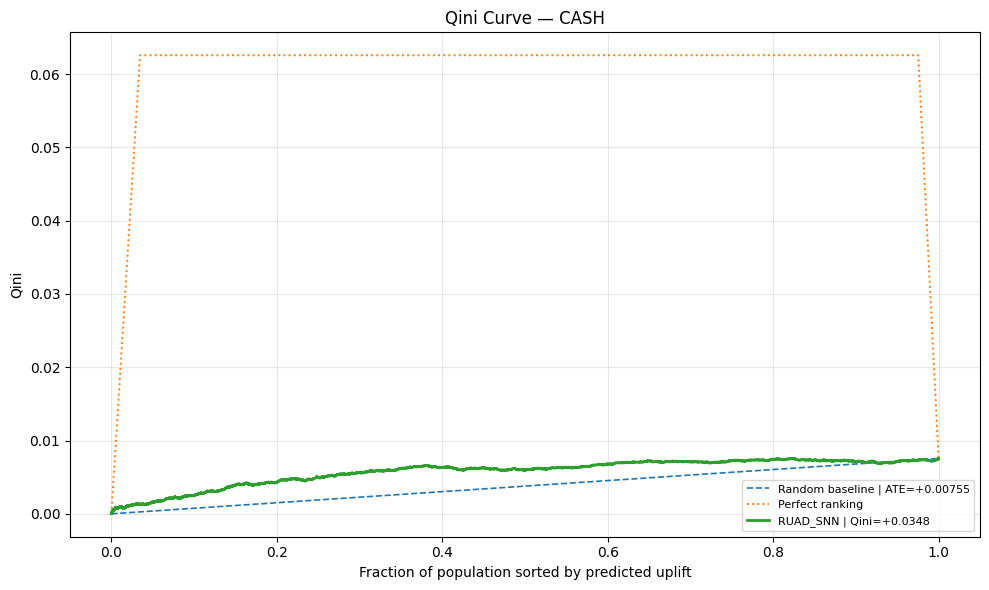

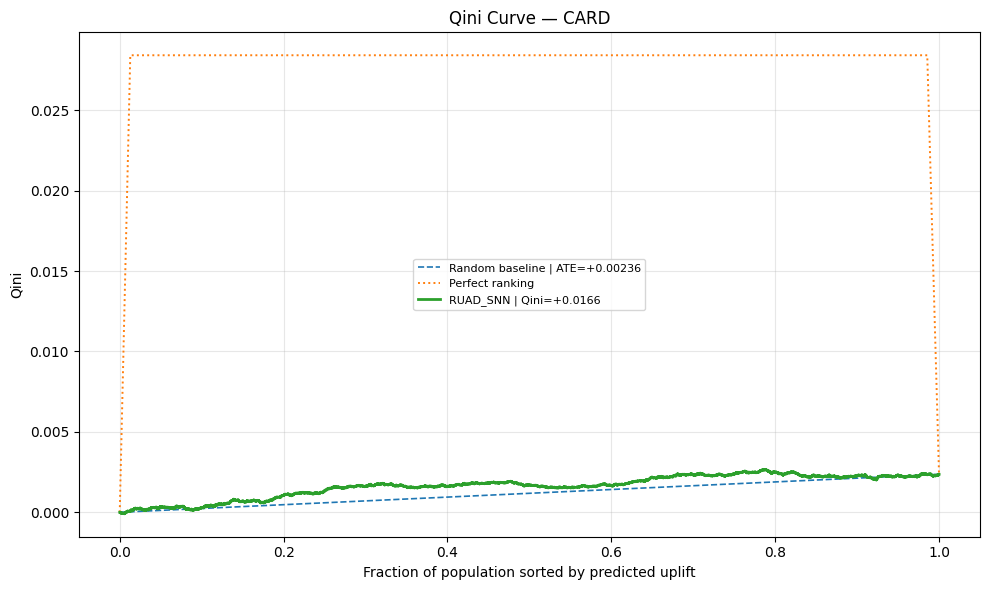

In [10]:
# ============================================================
# 11. QINI CURVES
# ============================================================
def plot_qini_compare(target_name, y, w_event, score_dict):
    if not score_dict:
        print(f"No scores for {target_name}")
        return

    plt.figure(figsize=(10, 6))
    xp, qp = qini_curve(y, w_event, oracle_score(y, w_event))
    ate = qp[-1]
    plt.plot([0, 1], [0, ate], "--", linewidth=1.2, label=f"Random baseline | ATE={ate:+.5f}")
    plt.plot(xp, qp, ":", linewidth=1.4, label="Perfect ranking")

    for model_name, score in score_dict.items():
        x, q = qini_curve(y, w_event, score)
        m = qini_metrics(y, w_event, score)
        plt.plot(x, q, linewidth=2, label=f"{model_name} | Qini={m['qini_norm']:+.4f}")

    plt.title(f"Qini Curve — {target_name.upper()}")
    plt.xlabel("Fraction of population sorted by predicted uplift")
    plt.ylabel("Qini")
    plt.grid(alpha=0.3)
    plt.legend(fontsize=8)
    plt.tight_layout()
    plt.show()


plot_qini_compare("cash", Y_cash, w_cash, scores_oof["cash"])
plot_qini_compare("card", Y_card, w_card, scores_oof["card"])


## 8. Export outputs

In [11]:
# ============================================================
# 12. EXPORT OUTPUTS
# ============================================================
def _safe_run_name(text, max_len=80):
    text = "baseline_all_features" if text is None else str(text)
    text = re.sub(r"[^A-Za-z0-9_.-]+", "_", text)
    return text[:max_len].strip("_") or "run"


BASE_OUTPUT_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("outputs")
if not FEATURE_DROP_BASE_COLS:
    RUN_TAG = "baseline_all_features"
else:
    id_part = "ids_" + "-".join("NA" if i is None else str(i) for i in FEATURE_DROP_IDXS)
    name_part = _safe_run_name("__".join(FEATURE_DROP_BASE_COLS), max_len=100)
    RUN_TAG = f"drop_{id_part}_{name_part}"

OUTPUT_DIR = BASE_OUTPUT_DIR / RUN_TAG
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Output dir:", OUTPUT_DIR)

summary_path = OUTPUT_DIR / "qini_summary.csv"
summary.to_csv(summary_path, index=False)
print("Saved:", summary_path)

fold_path = OUTPUT_DIR / "fold_qini_logs.csv"
fold_qini_logs.to_csv(fold_path, index=False)
print("Saved:", fold_path)

fold_mean_path = OUTPUT_DIR / "fold_mean_qini_by_model.csv"
fold_mean_qini_by_model.to_csv(fold_mean_path, index=False)
print("Saved:", fold_mean_path)

run_log_df = pd.DataFrame(run_log)
run_log_path = OUTPUT_DIR / "run_log.csv"
run_log_df.to_csv(run_log_path, index=False)
print("Saved:", run_log_path)

train_id = make_id_series(feat, id_col=ID_COL)

oof_out = pd.DataFrame()
oof_out[train_id.name] = train_id.values
oof_out["treatment_cash"] = W
oof_out["cash_sign_30d"] = Y_cash
oof_out["card_sign_30d"] = Y_card
oof_out["feature_drop_base_col"] = FEATURE_DROP_BASE_COL
oof_out["feature_drop_col_idx"] = FEATURE_DROP_COL_IDX
oof_out["feature_drop_n_base_cols"] = len(FEATURE_DROP_BASE_COLS)
for name, score in scores_oof["cash"].items():
    oof_out[f"cash_{name}"] = score
for name, score in scores_oof["card"].items():
    oof_out[f"card_{name}"] = score

oof_path = OUTPUT_DIR / "oof_model_scores.csv"
oof_out.to_csv(oof_path, index=False)
print("Saved:", oof_path)

if best_model is not None:
    final_train = pd.DataFrame()
    final_train[train_id.name] = train_id.values
    final_train["feature_drop_base_col"] = FEATURE_DROP_BASE_COL
    final_train["feature_drop_col_idx"] = FEATURE_DROP_COL_IDX
    final_train["feature_drop_n_base_cols"] = len(FEATURE_DROP_BASE_COLS)
    final_train["best_model"] = best_model
    final_train["uplift_cash_score"] = scores_oof["cash"][best_model]
    final_train["uplift_card_score"] = scores_oof["card"][best_model]
    final_train["cash_vs_card_score"] = final_train["uplift_cash_score"] - final_train["uplift_card_score"]
    final_train["recommended_product"] = np.where(final_train["cash_vs_card_score"] >= 0, "Cash", "Card")

    final_train_path = OUTPUT_DIR / "final_scores_train.csv"
    final_train.to_csv(final_train_path, index=False)
    print("Saved:", final_train_path)

    if X_test is not None and best_model in scores_test["cash"] and best_model in scores_test["card"]:
        submission = pd.DataFrame()
        submission[test_id.name] = test_id.values
        submission["best_model"] = best_model
        submission["uplift_cash_score"] = scores_test["cash"][best_model]
        submission["uplift_card_score"] = scores_test["card"][best_model]
        submission["cash_vs_card_score"] = submission["uplift_cash_score"] - submission["uplift_card_score"]
        submission["recommended_product"] = np.where(submission["cash_vs_card_score"] >= 0, "Cash", "Card")

        submission_path = OUTPUT_DIR / "submission.csv"
        submission.to_csv(submission_path, index=False)
        print("Saved:", submission_path)
    else:
        print("Skip submission: không có X_test hoặc best_model không có test score.")
else:
    print("Skip final score export: không có best_model.")

feature_drop_result = {
    "COL_IDX_config": str(COL_IDX),
    "feature_drop_col_idx": FEATURE_DROP_COL_IDX,
    "feature_drop_base_col": FEATURE_DROP_BASE_COL,
    "n_feature_drop_base_cols": len(FEATURE_DROP_BASE_COLS),
    "feature_drop_base_cols": "|".join(FEATURE_DROP_BASE_COLS),
    "n_dropped_train_cols": len(drop_cols_in_feat),
    "dropped_train_cols": "|".join(drop_cols_in_feat),
    "n_features_after_drop": len(FEAT_COLS),
    "best_model": best_model,
}
if best_model is not None:
    best_row = summary.iloc[0].to_dict()
    feature_drop_result.update({
        "best_Qini_coefficient_cash": best_row["Qini_coefficient_cash"],
        "best_Qini_coefficient_card": best_row["Qini_coefficient_card"],
        "best_Qini_coefficient_total": best_row["Qini_coefficient_total"],
    })

feature_drop_result_path = OUTPUT_DIR / "feature_drop_result.csv"
pd.DataFrame([feature_drop_result]).to_csv(feature_drop_result_path, index=False)
print("Saved:", feature_drop_result_path)


Output dir: /kaggle/working/baseline_all_features
Saved: /kaggle/working/baseline_all_features/qini_summary.csv
Saved: /kaggle/working/baseline_all_features/fold_qini_logs.csv
Saved: /kaggle/working/baseline_all_features/fold_mean_qini_by_model.csv
Saved: /kaggle/working/baseline_all_features/run_log.csv
Saved: /kaggle/working/baseline_all_features/oof_model_scores.csv
Saved: /kaggle/working/baseline_all_features/final_scores_train.csv
Skip submission: không có X_test hoặc best_model không có test score.
Saved: /kaggle/working/baseline_all_features/feature_drop_result.csv


## 9. Cách đọc kết quả

Các file quan trọng sau khi chạy:

- `qini_summary.csv`: Qini OOF của **RUAD_SNN**.
- `fold_qini_logs.csv`: Qini từng fold cho RUAD_SNN.
- `fold_mean_qini_by_model.csv`: Qini trung bình 5 fold.
- `feature_drop_result.csv`: file gọn nhất để so sánh các lần drop feature.
- `final_scores_train.csv`: score uplift Cash/Card và khuyến nghị Cash/Card trên train.
- `submission.csv`: chỉ tạo nếu notebook tìm thấy test feature đã clean/one-hot tương thích với `df_feature.csv`.

Lưu ý:
- `RUAD_SNN` là model neural uplift tích hợp feature mask + transformed-outcome loss + adversarial feature desensitization.
- Notebook này không còn train `INT_RF` và không còn phụ thuộc `causalml` / `UPLIFT_RF_CIT`.